In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("quands/eeg-dataset")

print("Path to dataset files:", path)

100%|██████████| 3.01M/3.01M [00:00<00:00, 116MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/quands/eeg-dataset/versions/1


In [4]:
import os
print("Main folder:", os.listdir(path))
print("Dataset folder:", os.listdir(path + "/Dataset"))

Main folder: ['Dataset']
Dataset folder: ['N', 'S', 'F', 'Z', 'O']


In [5]:
#Load the dataset
import numpy as np
import os

data = []
labels = []

base_path = path + "/Dataset"

classes = sorted(os.listdir(base_path))  # ['F', 'N', 'O', 'S', 'Z']

for label, folder in enumerate(classes):
    folder_path = os.path.join(base_path, folder)

    for file in os.listdir(folder_path):
        file_path = os.path.join(folder_path, file)

        signal = np.loadtxt(file_path)   # read EEG signal

        data.append(signal)
        labels.append(label)

X = np.array(data)
y = np.array(labels)

print("Data shape:", X.shape)   # (500, timesteps) total samples=500
print("Labels shape:", y.shape)

Data shape: (500, 4097)
Labels shape: (500,)


In [6]:
#Normalize Data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)


In [7]:
#Reshape for CNN
X = X.reshape(X.shape[0], X.shape[1], 1)

print("New shape:", X.shape)

New shape: (500, 4097, 1)


In [8]:
#Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
import numpy as np

print("Training Samples per Class:")
for i, cls in enumerate(classes):
    count = np.sum(y_train == i)
    print(f"{cls}: {count}")

Training Samples per Class:
F: 72
N: 86
O: 90
S: 76
Z: 76


In [10]:
print("Testing Samples per Class:")
for i, cls in enumerate(classes):
    count = np.sum(y_test == i)
    print(f"{cls}: {count}")

Testing Samples per Class:
F: 28
N: 14
O: 10
S: 24
Z: 24


In [11]:
#Build 1D CNN Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout

model = Sequential()

model.add(Conv1D(32, 3, activation='relu', input_shape=(X.shape[1], 1)))
model.add(MaxPooling1D(2))

model.add(Conv1D(64, 3, activation='relu'))
model.add(MaxPooling1D(2))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(5, activation='softmax'))  # 5 classes

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 4095, 32)       │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2047, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2045, 64)       │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 1022, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65408)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     8,372,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,379,333 (31.96 MB)

 Trainable params: 8,379,333 (31.96 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
#Compile Model
model.compile(
    optimizer="adam",
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
history = model.fit(
    X_train, y_train,
    epochs=20,          # allow learning
    batch_size=32,      # smaller = better generalization
    validation_data=(X_test, y_test),
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 293ms/step - accuracy: 0.2425 - loss: 2.2514 - val_accuracy: 0.3900 - val_loss: 1.3243
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 327ms/step - accuracy: 0.4750 - loss: 1.2616 - val_accuracy: 0.6300 - val_loss: 1.1228
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 255ms/step - accuracy: 0.6500 - loss: 0.9457 - val_accuracy: 0.6300 - val_loss: 0.9249
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 263ms/step - accuracy: 0.7100 - loss: 0.7358 - val_accuracy: 0.8100 - val_loss: 0.7318
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 433ms/step - accuracy: 0.7900 - loss: 0.6046 - val_accuracy: 0.6900 - val_loss: 0.8017
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 267ms/step - accuracy: 0.8025 - loss: 0.5346 - val_accuracy: 0.8200 - val_loss: 0.6716
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 302ms/step - accuracy: 0.8550 - loss: 0.4547 - val_accuracy: 0.8000 - val_loss: 0.5854
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 263ms/step - accuracy: 0.9025 - loss: 0.3275 - val_accuracy: 0.

In [16]:
#Evaluate Model
loss, acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", acc)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7800 - loss: 0.7101
Test Accuracy: 0.7799999713897705


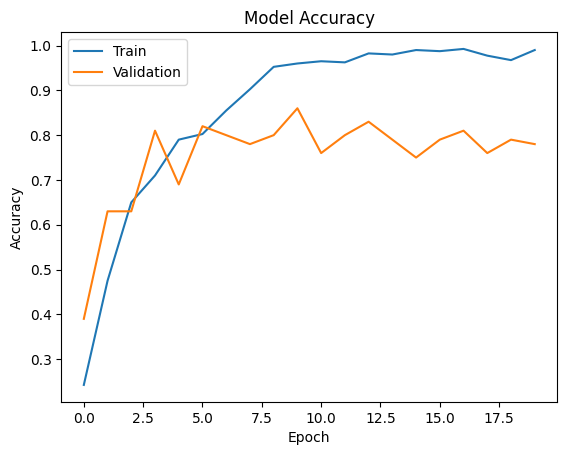

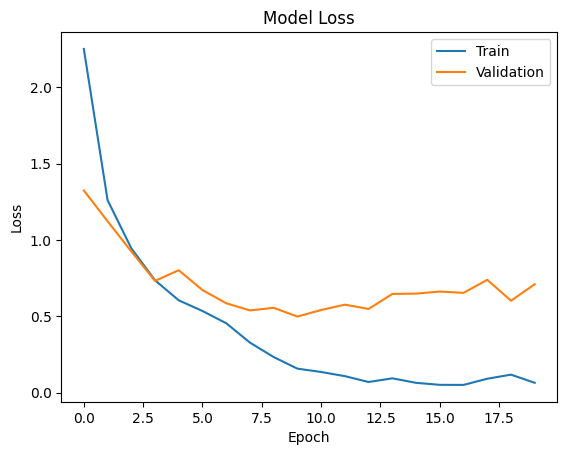

In [17]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

# Loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()

In [18]:
#Predictions
import numpy as np

y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


In [19]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_classes)
print(cm)

[[22  3  1  0  2]
 [ 0 13  1  0  0]
 [ 0  0  7  0  3]
 [ 0  0  4 20  0]
 [ 0  2  6  0 16]]


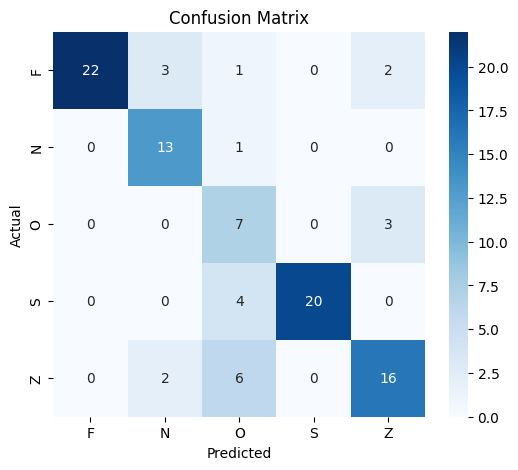

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

classes = ['F', 'N', 'O', 'S', 'Z']

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes,
            yticklabels=classes)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_classes, target_names=['F','N','O','S','Z']))

              precision    recall  f1-score   support

           F       1.00      0.79      0.88        28
           N       0.72      0.93      0.81        14
           O       0.37      0.70      0.48        10
           S       1.00      0.83      0.91        24
           Z       0.76      0.67      0.71        24

    accuracy                           0.78       100
   macro avg       0.77      0.78      0.76       100
weighted avg       0.84      0.78      0.80       100



In [23]:
from sklearn.model_selection import StratifiedKFold
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_accuracies = []
fold_no = 1

for train_index, test_index in kf.split(X, y):

    print(f"\n🔹 Fold {fold_no}")

    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Build model
    model = Sequential()

    model.add(Conv1D(32, 3, activation='relu', input_shape=(X.shape[1],1)))
    model.add(MaxPooling1D(2))

    model.add(Conv1D(64, 3, activation='relu'))
    model.add(MaxPooling1D(2))

    model.add(Flatten())

    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.5))

    model.add(Dense(5, activation='softmax'))

    # Compile
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Train
    model.fit(
        X_train, y_train,
        epochs=20,
        batch_size=32,
        verbose=0
    )

    # Evaluate
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"Accuracy: {acc:.4f}")

    fold_accuracies.append(acc)
    fold_no += 1

# Final Result
print("\nK-Fold Accuracies:", fold_accuracies)
print("Average Accuracy:", np.mean(fold_accuracies))


🔹 Fold 1


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy: 0.8000

🔹 Fold 2
Accuracy: 0.8400

🔹 Fold 3
Accuracy: 0.8400

🔹 Fold 4
Accuracy: 0.8400

🔹 Fold 5
Accuracy: 0.8200

K-Fold Accuracies: [0.800000011920929, 0.8399999737739563, 0.8399999737739563, 0.8399999737739563, 0.8199999928474426]
Average Accuracy: 0.8279999852180481



🔹 Fold 1


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


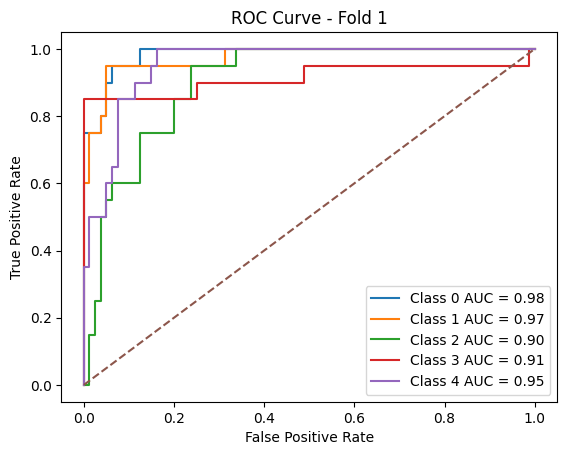


🔹 Fold 2


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


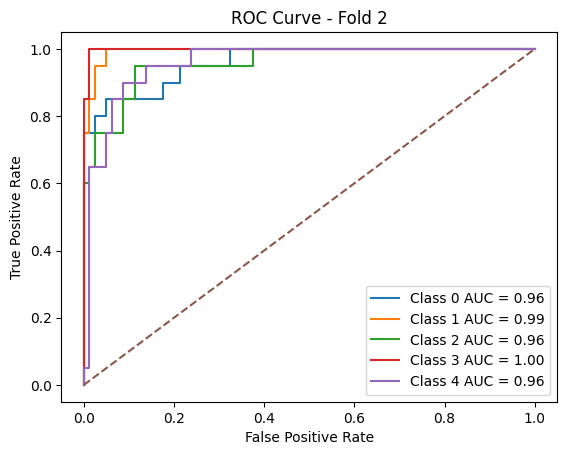


🔹 Fold 3


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step


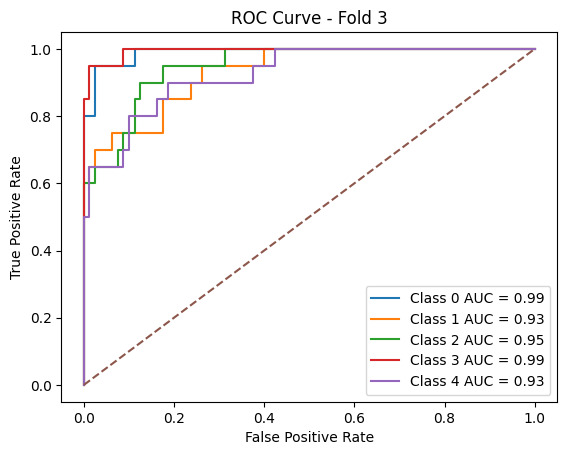


🔹 Fold 4


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


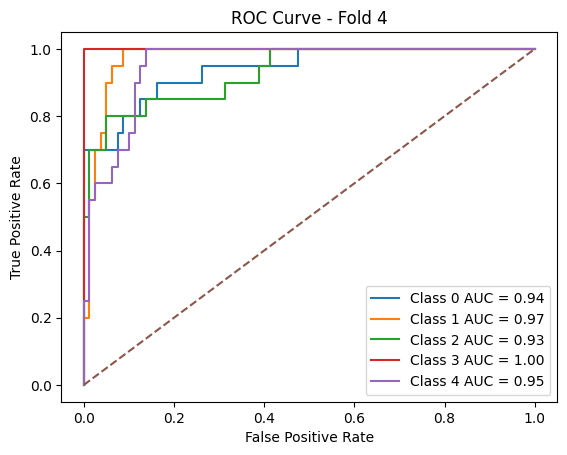


🔹 Fold 5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


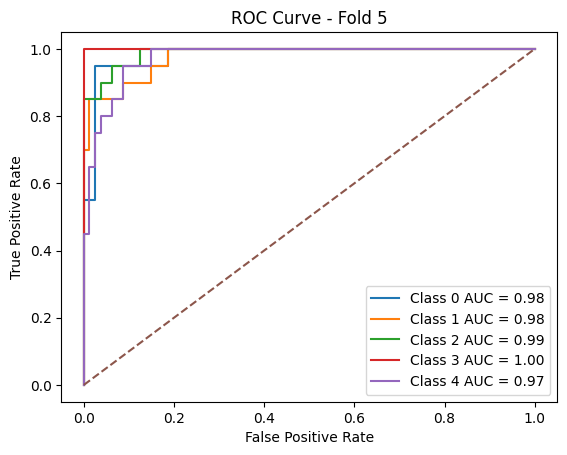

In [24]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout

# Binarize labels for ROC
y_bin = label_binarize(y, classes=[0,1,2,3,4])
n_classes = y_bin.shape[1]

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_no = 1

for train_index, test_index in kf.split(X, y):

    print(f"\n🔹 Fold {fold_no}")

    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    y_test_bin = y_bin[test_index]

    # Build model
    model = Sequential()

    model.add(Conv1D(32, 3, activation='relu', input_shape=(X.shape[1],1)))
    model.add(MaxPooling1D(2))

    model.add(Conv1D(64, 3, activation='relu'))
    model.add(MaxPooling1D(2))

    model.add(Flatten())

    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.5))

    model.add(Dense(5, activation='softmax'))

    # Compile
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Train
    model.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)

    # Predict probabilities
    y_score = model.predict(X_test)

    # ROC for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Plot ROC curves
    plt.figure()
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], label=f'Class {i} AUC = {roc_auc[i]:.2f}')

    plt.plot([0,1], [0,1], linestyle='--')  # diagonal
    plt.title(f'ROC Curve - Fold {fold_no}')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()
    plt.show()

    fold_no += 1

In [26]:
#Prepare binary labels
import numpy as np
import os

# Use the raw signals already loaded in your notebook
X_raw = np.asarray(data, dtype=np.float32)

# Recreate the folder-to-label mapping
folder_names = sorted(os.listdir(base_path))
original_labels = np.asarray(labels, dtype=int)

folder_for_sample = np.array([
    folder_names[i] for i in original_labels
])

# S = seizure; all other folders = non-seizure
y_binary = (folder_for_sample == "S").astype(np.int32)

print("Raw EEG shape:", X_raw.shape)
print("Binary labels shape:", y_binary.shape)
print("Non-seizure samples:", np.sum(y_binary == 0))
print("Seizure samples:", np.sum(y_binary == 1))

Raw EEG shape: (500, 4097)
Binary labels shape: (500,)
Non-seizure samples: 400
Seizure samples: 100


In [27]:
#Split and normalize the data correctly
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

scaler_binary = StandardScaler()

X_train = scaler_binary.fit_transform(X_train_raw)
X_test = scaler_binary.transform(X_test_raw)

# CNN requires shape: samples, timesteps, channels
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training seizure samples:", np.sum(y_train == 1))
print("Testing seizure samples:", np.sum(y_test == 1))

Training data: (400, 4097, 1)
Testing data: (100, 4097, 1)
Training seizure samples: 80
Testing seizure samples: 20


In [28]:
#Build the binary CNN model
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

binary_model = Sequential([
    Input(shape=(X_train.shape[1], 1)),

    Conv1D(32, 7, activation="relu"),
    MaxPooling1D(2),

    Conv1D(64, 5, activation="relu"),
    MaxPooling1D(2),

    GlobalAveragePooling1D(),
    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(1, activation="sigmoid")
])

binary_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_binary = binary_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 151ms/step - accuracy: 0.8094 - loss: 0.6575 - precision: 0.5169 - recall: 0.7188 - val_accuracy: 0.8875 - val_loss: 0.6106 - val_precision: 0.7333 - val_recall: 0.6875
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 161ms/step - accuracy: 0.9438 - loss: 0.5459 - precision: 0.8966 - recall: 0.8125 - val_accuracy: 0.9375 - val_loss: 0.4519 - val_precision: 1.0000 - val_recall: 0.6875
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 236ms/step - accuracy: 0.9531 - loss: 0.3406 - precision: 1.0000 - recall: 0.7656 - val_accuracy: 0.9375 - val_loss: 0.2440 - val_precision: 1.0000 - val_recall: 0.6875
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.9563 - loss: 0.1707 - precision: 0.9464 - recall: 0.8281 - val_accuracy: 0.9125 - val_loss: 0.1578 - val_precision: 0.8462 - val_recall: 0.6875
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.9563 - loss: 0.1274 - precision: 0.9464 - recall: 0.8281 - val_accuracy: 0.9125 - val_loss: 0.

              precision    recall  f1-score   support

  No Seizure       0.99      0.96      0.97        80
     Seizure       0.86      0.95      0.90        20

    accuracy                           0.96       100
   macro avg       0.93      0.96      0.94       100
weighted avg       0.96      0.96      0.96       100

Confusion matrix:
[[77  3]
 [ 1 19]]
ROC-AUC: 0.9881


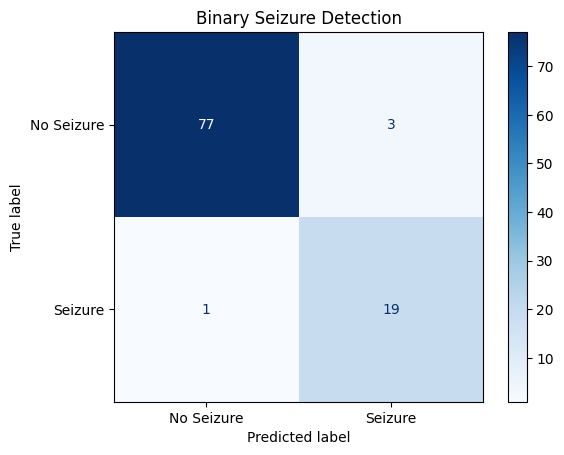

In [29]:
#Evaluate seizure detection
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt

probabilities = binary_model.predict(X_test, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["No Seizure", "Seizure"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, predictions))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=[0, 1],
    display_labels=["No Seizure", "Seizure"],
    cmap="Blues"
)
plt.title("Binary Seizure Detection")
plt.show()

In [30]:
import joblib

binary_model.save("/content/seizure_detection_model.keras")
joblib.dump(scaler_binary, "/content/eeg_scaler.pkl")

print("CNN model and scaler saved!")

CNN model and scaler saved!


In [31]:
sample = X_test[0:1]

probability = float(
    binary_model.predict(sample, verbose=0)[0][0]
)

if probability >= 0.5:
    print("Prediction: SEIZURE")
else:
    print("Prediction: NO SEIZURE")

print(f"Model seizure score: {probability:.2%}")
print("Actual class:", "SEIZURE" if y_test[0] == 1
      else "NO SEIZURE")

Prediction: NO SEIZURE
Model seizure score: 0.03%
Actual class: NO SEIZURE


In [32]:
def predict_eeg(file_path):
    # Load raw EEG signal
    signal = np.loadtxt(file_path)

    if signal.ndim != 1 or len(signal) != X_raw.shape[1]:
        raise ValueError(
            f"Expected a 1D EEG signal with "
            f"{X_raw.shape[1]} values."
        )

    # Apply the same training scaler
    signal = scaler_binary.transform(
        signal.reshape(1, -1)
    )

    # Add CNN channel dimension
    signal = signal[..., np.newaxis]

    # Predict
    score = float(
        binary_model.predict(signal, verbose=0)[0][0]
    )

    result = "SEIZURE" if score >= 0.5 else "NO SEIZURE"

    print("Prediction:", result)
    print(f"Seizure score: {score:.2%}")

    return result, score

In [33]:
!pip install -q gradio

In [34]:

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt

def predict_eeg_interface(file_path):
    if file_path is None:
        return "Please upload an EEG signal file.", None, None

    try:
        # Load the EEG signal from a TXT or CSV file
        try:
            signal = np.loadtxt(file_path)
        except ValueError:
            signal = np.loadtxt(file_path, delimiter=",")

        signal = np.asarray(signal, dtype=np.float32).squeeze()

        if signal.ndim != 1:
            return "Error: Please upload a file containing one EEG signal.", None, None

        # Check expected signal length
        expected_length = scaler_binary.n_features_in_

        if len(signal) != expected_length:
            return (
                f"Expected {expected_length} values, but received {len(signal)}.",
                None,
                None
            )

        # Apply the same preprocessing used during training
        scaled_signal = scaler_binary.transform(
            signal.reshape(1, -1)
        )
        model_input = scaled_signal[..., np.newaxis]

        # Predict using the existing trained CNN
        score = float(
            binary_model.predict(model_input, verbose=0).ravel()[0]
        )

        prediction = "SEIZURE" if score >= 0.5 else "NO SEIZURE"

        result = (
            f"Prediction: {prediction}\n"
            f"Model seizure score: {score:.2%}"
        )

        # Plot the EEG waveform
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(signal, linewidth=0.8)
        ax.set_title("Uploaded EEG Signal")
        ax.set_xlabel("Sample")
        ax.set_ylabel("Signal Amplitude")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()

        # Display the model score
        fig_score, ax_score = plt.subplots(figsize=(6, 2))
        ax_score.barh(
            ["Seizure score", "Other"],
            [score, 1 - score]
        )
        ax_score.set_xlim(0, 1)
        ax_score.set_xlabel("Model score")
        ax_score.set_title("Model Output Scores")
        fig_score.tight_layout()

        return result, fig, fig_score

    except Exception as e:
        return f"Error: {str(e)}", None, None


with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        """
        # 🧠 EEG Seizure Detection
        ### AI-powered EEG signal classification

        Upload one EEG signal as a `.txt` or `.csv` file.
        """
    )

    file_input = gr.File(
        label="Upload EEG Signal",
        type="filepath",
        file_types=[".txt", ".csv"]
    )

    predict_button = gr.Button(
        "Analyze EEG Signal",
        variant="primary"
    )

    result_output = gr.Textbox(
        label="Prediction Result",
        lines=2
    )

    signal_plot = gr.Plot(label="EEG Waveform")
    score_plot = gr.Plot(label="Model Output Scores")

    predict_button.click(
        fn=predict_eeg_interface,
        inputs=file_input,
        outputs=[result_output, signal_plot, score_plot]
    )

demo.launch(share=True)


/tmp/ipykernel_1563/1127546989.py:75: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b0891e530fc8545e16.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
